<a href="https://colab.research.google.com/github/mehjabin-momo/Mushroom-Classification-with-Supervised-and-Unsupervised-Learning/blob/main/CSE422_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mushroom Classification with Supervised and Unsupervised Learning

**Author:** [Iftekhar Mohammed Aritro, Mehjabin Mostare Momo]

**Project Objective:**
This project conducts an end-to-end machine learning workflow on a mushroom dataset. The primary goal is to develop a highly accurate classification model to determine whether a mushroom is edible or poisonous based on its physical characteristics.

**Methodology:**
The project follows a structured pipeline as referenced in the provided lab materials:
1.  **Exploratory Data Analysis (EDA):** To understand the dataset's structure, identify quality issues, and analyze feature distributions.
2.  **Data Preprocessing:** To clean the data by handling missing values and transforming features into a format suitable for machine learning algorithms.
3.  **Supervised Learning:** To train and evaluate several classification models, including a Decision Tree, Logistic Regression, K-Nearest Neighbors, and a Neural Network.
4.  **Unsupervised Learning:** To apply K-Means clustering to discover natural groupings within the data.
5.  **Model Comparison:** To systematically compare the performance of all supervised models and draw a final conclusion.

In [ ]:
# --- Core Libraries for Data Handling and Visualization ---
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# --- Scikit-Learn for Preprocessing and Modeling ---
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# --- Visualization & Dimensionality Reduction ---
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans

# --- Supervised Learning Models ---
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# --- TensorFlow and Keras for the Neural Network ---
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

# --- Model Evaluation Metrics ---
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [ ]:
from google.colab import files
uploaded = files.upload()

#filename and read the uploaded file
filename = list(uploaded.keys())[0]
data = pd.read_csv(filename)
print(f"✅ Dataset '{filename}' loaded successfully.")

Saving mushroom_dataset.csv to mushroom_dataset.csv
✅ Dataset 'mushroom_dataset.csv' loaded successfully.


## 1. Exploratory Data Analysis (EDA)
 EDA is the process of examining a dataset to summarize its main characteristics. We will perform an initial investigation to understand its structure, check for missing values, and analyze the target variable.

In [ ]:
print("--- Dataset Overview ---")
print(f"The dataset has {data.shape[0]} rows and {data.shape[1]} columns.")
print("\n--- First 5 Rows ---")
display(data.head())
print("\n--- Data Types and Non-Null Counts ---")
data.info()

--- Dataset Overview ---
The dataset has 61069 rows and 21 columns.

--- First 5 Rows ---


,class,cap-diameter,cap-shape,cap-surface,cap-color,does-bruise-or-bleed,gill-attachment,gill-spacing,gill-color,stem-height,...,stem-root,stem-surface,stem-color,veil-type,veil-color,has-ring,ring-type,spore-print-color,habitat,season
0,p,15.26,x,g,o,f,e,NaN,w,16.95,...,s,y,w,u,w,t,g,NaN,d,w
1,p,16.60,x,g,o,f,e,NaN,w,17.99,...,s,y,w,u,w,t,g,NaN,d,u
2,p,14.07,x,g,o,f,e,NaN,w,17.80,...,s,y,w,u,w,t,g,NaN,d,w
3,p,14.17,f,h,e,f,e,NaN,w,15.77,...,s,y,w,u,w,t,p,NaN,d,w
4,p,14.64,x,h,o,f,e,NaN,w,16.53,...,s,y,w,u,w,t,p,NaN,d,w



--- Data Types and Non-Null Counts ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61069 entries, 0 to 61068
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   class                 61069 non-null  object 
 1   cap-diameter          61069 non-null  float64
 2   cap-shape             61069 non-null  object 
 3   cap-surface           46949 non-null  object 
 4   cap-color             61069 non-null  object 
 5   does-bruise-or-bleed  61069 non-null  object 
 6   gill-attachment       51185 non-null  object 
 7   gill-spacing          36006 non-null  object 
 8   gill-color            61069 non-null  object 
 9   stem-height           61069 non-null  float64
 10  stem-width            61069 non-null  float64
 11  stem-root             9531 non-null   object 
 12  stem-surface          22945 non-null  object 
 13  stem-color            61069 non-null  object 
 14  veil-type             3177 non

In [ ]:
null_counts = data.isnull().sum()
null_percentages = (null_counts / len(data)) * 100
null_df = pd.DataFrame({'Null Count': null_counts, 'Null Percentage': null_percentages})

print("--- Missing Value Analysis ---")
print(null_df.sort_values(by='Null Percentage', ascending=False))

--- Missing Value Analysis ---
                      Null Count  Null Percentage
veil-type                  57892        94.797688
spore-print-color          54715        89.595376
veil-color                 53656        87.861272
stem-root                  51538        84.393064
stem-surface               38124        62.427746
gill-spacing               25063        41.040462
cap-surface                14120        23.121387
gill-attachment             9884        16.184971
ring-type                   2471         4.046243
cap-color                      0         0.000000
cap-shape                      0         0.000000
cap-diameter                   0         0.000000
class                          0         0.000000
stem-height                    0         0.000000
stem-width                     0         0.000000
does-bruise-or-bleed           0         0.000000
gill-color                     0         0.000000
has-ring                       0         0.000000
stem-color         

--- Target Variable Distribution ('class') ---
class
p    33888
e    27181
Name: count, dtype: int64


/tmp/ipython-input-371488475.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='class', data=data, palette=['#1f77b4', '#ff7f0e'])


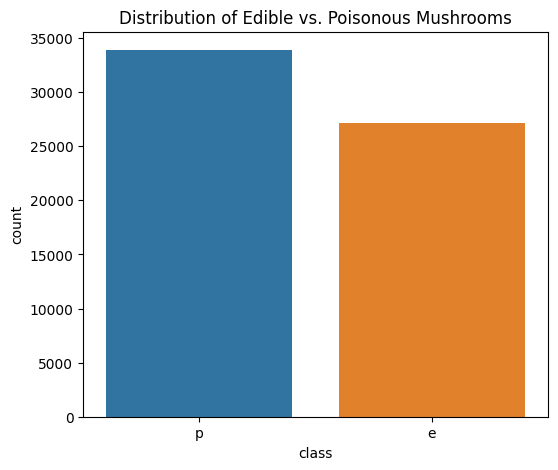

Observation: The dataset is well-balanced, so no resampling techniques are required.


In [ ]:
print("--- Target Variable Distribution ('class') ---")
print(data['class'].value_counts())

plt.figure(figsize=(6, 5))
sns.countplot(x='class', data=data, palette=['#1f77b4', '#ff7f0e'])
plt.title('Distribution of Edible vs. Poisonous Mushrooms')
plt.show()

print("Observation: The dataset is well-balanced, so no resampling techniques are required.")

## 2. Data Preprocessing
we now prepare the data for modeling. Our process is:
1.  **Drop Unreliable Columns:** Remove features with >60% missing values.
2.  **Impute Remaining Nulls:** Fill smaller data gaps using the mode.
3.  **Feature Engineering:** Encode categorical features and scale numerical features.
4.  **Data Splitting:** Divide the data into training and testing sets.

In [ ]:
#droped the 5 columns with over 60% missing values.
columns_to_drop = ['stem-root', 'stem-surface', 'veil-type', 'veil-color', 'spore-print-color']
data.drop(columns=columns_to_drop, inplace=True)

print(f"✅ Dropped 5 columns. New dataset shape: {data.shape}")

✅ Dropped 5 columns. New dataset shape: (61069, 16)


In [ ]:
# # PARTIAL imputation
# cols_to_partially_impute = {
#     "gill-spacing": 20000,
#     "cap-surface": 10000,
#     "gill-attachment": 5000
# }

# print("--- Performing Partial Imputation ---")
# for col, num_to_impute in cols_to_partially_impute.items():
#     current_null_count = data[col].isnull().sum()
#     if current_null_count >= num_to_impute:
#         mode_value = data[col].mode()[0]
#         null_indices = data[data[col].isnull()].index
#         indices_to_fill = np.random.choice(null_indices, size=num_to_impute, replace=False)
#         data.loc[indices_to_fill, col] = mode_value
#         print(f"Imputed {num_to_impute} nulls in '{col}'. Remaining nulls: {data[col].isnull().sum()}")
#     else:
#         print(f"Skipped '{col}', not enough nulls to impute.")

# print(f"\nTotal nulls remaining in dataset after partial imputation: {data.isnull().sum().sum()}")

--- Performing Partial Imputation ---
Imputed 20000 nulls in 'gill-spacing'. Remaining nulls: 5063
Imputed 10000 nulls in 'cap-surface'. Remaining nulls: 4120
Imputed 5000 nulls in 'gill-attachment'. Remaining nulls: 4884

Total nulls remaining in dataset after partial imputation: 16538


In [ ]:
cols_to_impute = data.columns[data.isnull().any()].tolist()
print(f"Columns to impute: {cols_to_impute}")
for col in cols_to_impute:
    imputer = SimpleImputer(strategy='most_frequent')
    data[col] = imputer.fit_transform(data[[col]]).ravel()
print(f"✅ Imputation complete. Total null values remaining: {data.isnull().sum().sum()}")

Columns to impute: ['cap-surface', 'gill-attachment', 'gill-spacing', 'ring-type']
✅ Imputation complete. Total null values remaining: 0


✅ Preprocessing and data splitting complete.
Training set shape: (48855, 92)
Testing set shape: (12214, 92)

--- Data Table: First 5 Rows of Final Processed Data ---


,num__cap-diameter,num__stem-height,num__stem-width,cat__cap-shape_b,cat__cap-shape_c,cat__cap-shape_f,cat__cap-shape_o,cat__cap-shape_p,cat__cap-shape_s,cat__cap-shape_x,...,cat__habitat_h,cat__habitat_l,cat__habitat_m,cat__habitat_p,cat__habitat_u,cat__habitat_w,cat__season_a,cat__season_s,cat__season_u,cat__season_w
0,1.619462,3.076705,0.492293,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,1.873982,3.385311,0.601900,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,1.393432,3.328931,0.557061,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,1.412426,2.726555,0.381690,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,1.501699,2.952075,0.503254,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0



--- Visualization: Effect of Scaling on a Numerical Feature ---


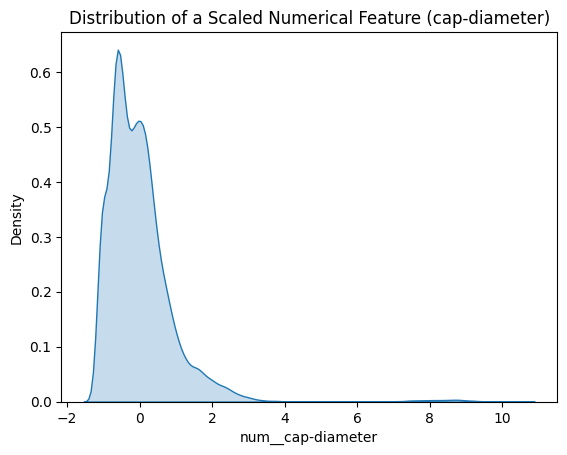

In [ ]:
#features (X) and target (y)
#encoding, scaling, and splits the data.
X = data.drop('class', axis=1)
y = data['class']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

#Define preprocessor
numerical_features = X.select_dtypes(include=np.number).columns
categorical_features = X.select_dtypes(include='object').columns
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ])

#Apply preprocessor
X_transformed = preprocessor.fit_transform(X)
new_column_names = preprocessor.get_feature_names_out()
X_transformed_df = pd.DataFrame(X_transformed, columns=new_column_names)

#split
X_train, X_test, y_train, y_test = train_test_split(
    X_transformed_df, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print("✅ Preprocessing and data splitting complete.")
print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)
print("\n--- Data Table: First 5 Rows of Final Processed Data ---")
display(X_transformed_df.head())

print("\n--- Visualization: Effect of Scaling on a Numerical Feature ---")
sns.kdeplot(X_transformed_df['num__cap-diameter'], fill=True)
plt.title('Distribution of a Scaled Numerical Feature (cap-diameter)')
plt.show()


##**3. Supervised Learning: Model Training**
In this section, we will initialize and fit our four required supervised learning models on the training data (X_train, y_train).

In [ ]:
#Decision Tree model.

print("--- Training Model 1: Decision Tree Classifier ---")
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
print("✅ Decision Tree model trained successfully.")

--- Training Model 1: Decision Tree Classifier ---
✅ Decision Tree model trained successfully.


In [ ]:
#Logistic Regression model.

print("--- Training Model 2: Logistic Regression ---")
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)
print("✅ Logistic Regression model trained successfully.")

--- Training Model 2: Logistic Regression ---
✅ Logistic Regression model trained successfully.


In [ ]:
#K-Nearest Neighbors model.

print("--- Training Model 3: K-Nearest Neighbors (KNN) ---")
knn_model = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn_model.fit(X_train, y_train)
print("✅ KNN model trained successfully.")

--- Training Model 3: K-Nearest Neighbors (KNN) ---
✅ KNN model trained successfully.


In [ ]:
#Neural Network model.

print("--- Training Model 4: Neural Network (TensorFlow/Keras) ---")
nn_model_keras = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])
nn_model_keras.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

history = nn_model_keras.fit(
    X_train, y_train,
    epochs=10, batch_size=128,
    validation_split=0.1, verbose=0
)
print("✅ Neural Network model trained successfully.")

--- Training Model 4: Neural Network (TensorFlow/Keras) ---


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


✅ Neural Network model trained successfully.


## 4. Model Evaluation & Testing
Now that the models are trained, we will use them to make predictions on the unseen test data (`X_test`) and evaluate their performance using classification reports (data tables) and confusion matrices (visualizations).

--- Evaluating Model 1: Decision Tree ---

--- Data Table: Classification Report ---
              precision    recall  f1-score   support

           e       1.00      1.00      1.00      5436
           p       1.00      1.00      1.00      6778

    accuracy                           1.00     12214
   macro avg       1.00      1.00      1.00     12214
weighted avg       1.00      1.00      1.00     12214


--- Visualization: Confusion Matrix ---


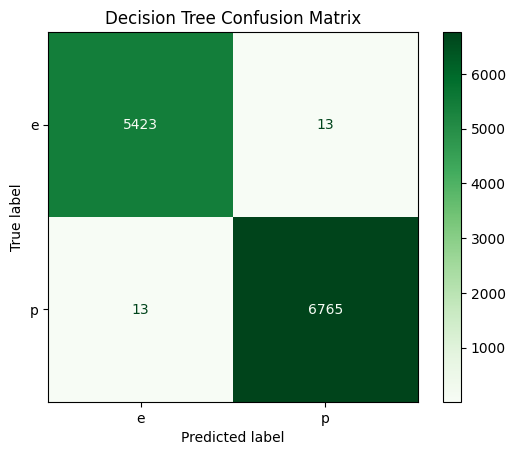

Generating Full Decision Tree


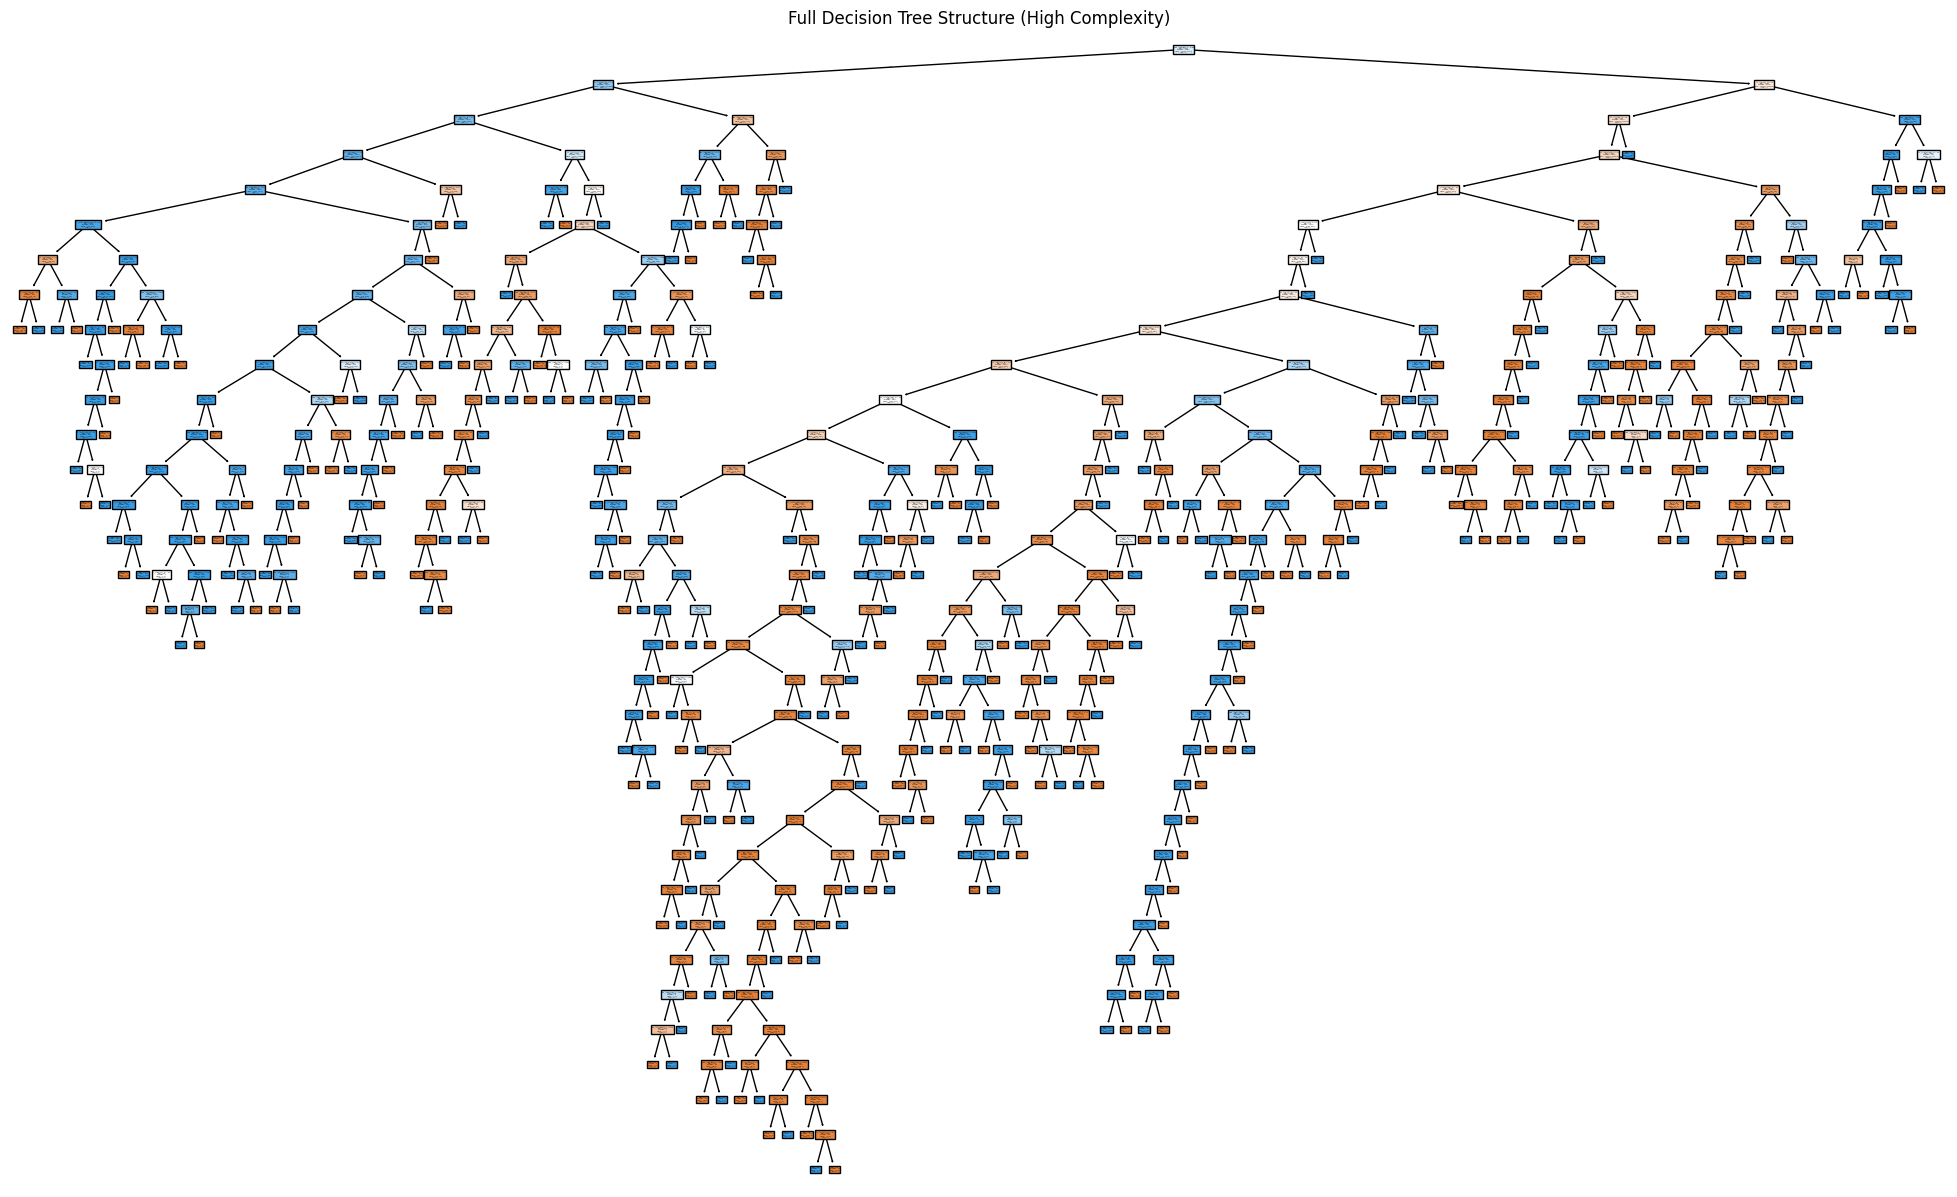


--- Generating Simplified Decision Tree (max_depth=3) ---


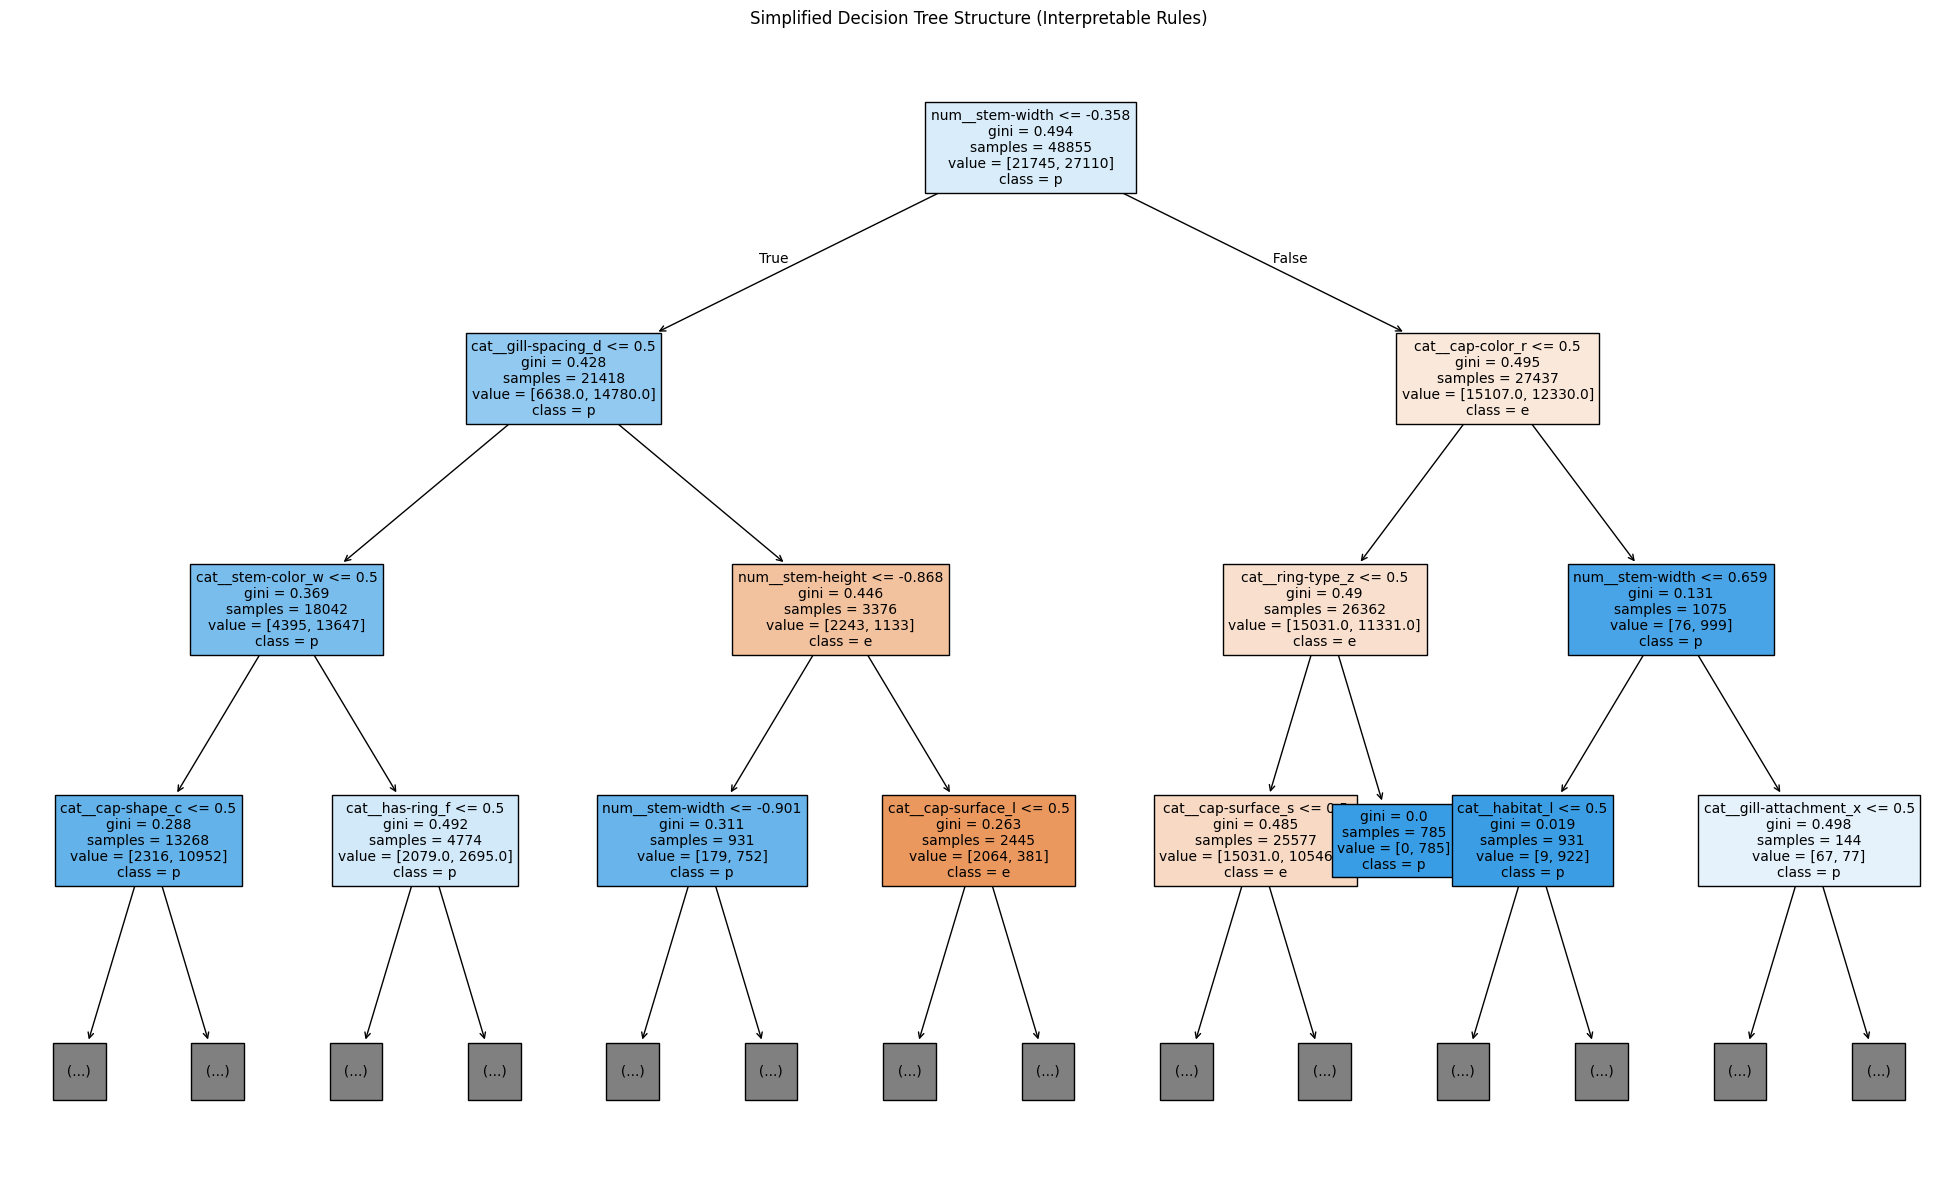

In [ ]:
print("--- Evaluating Model 1: Decision Tree ---")
y_pred_dt = dt_model.predict(X_test)

print("\n--- Data Table: Classification Report ---")
print(classification_report(y_test, y_pred_dt, target_names=le.classes_))

print("\n--- Visualization: Confusion Matrix ---")
cm_dt = confusion_matrix(y_test, y_pred_dt)
ConfusionMatrixDisplay(cm_dt, display_labels=le.classes_).plot(cmap="Greens")
plt.title("Decision Tree Confusion Matrix")
plt.show()


from sklearn.tree import plot_tree


print("Generating Full Decision Tree")
plt.figure(figsize=(25, 15))
plot_tree(dt_model, filled=True, feature_names=X_train.columns, class_names=[le.classes_[0], le.classes_[1]])
plt.title("Full Decision Tree Structure (High Complexity)")
plt.show()


print("\n--- Generating Simplified Decision Tree (max_depth=3) ---")
plt.figure(figsize=(25, 15))
plot_tree(dt_model, max_depth=3, filled=True, feature_names=X_train.columns, class_names=[le.classes_[0], le.classes_[1]], fontsize=10)
plt.title("Simplified Decision Tree Structure (Interpretable Rules)")
plt.show()

--- Evaluating Model 2: Logistic Regression ---

--- Data Table: Classification Report ---
              precision    recall  f1-score   support

           e       0.75      0.75      0.75      5436
           p       0.80      0.80      0.80      6778

    accuracy                           0.78     12214
   macro avg       0.77      0.77      0.77     12214
weighted avg       0.78      0.78      0.78     12214


--- Visualization: Confusion Matrix ---


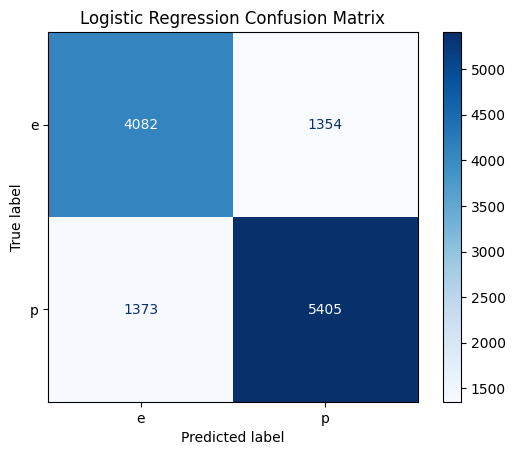

/tmp/ipython-input-3646371772.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='coefficient', y='feature', data=coef_df_sorted.head(20), palette='viridis')


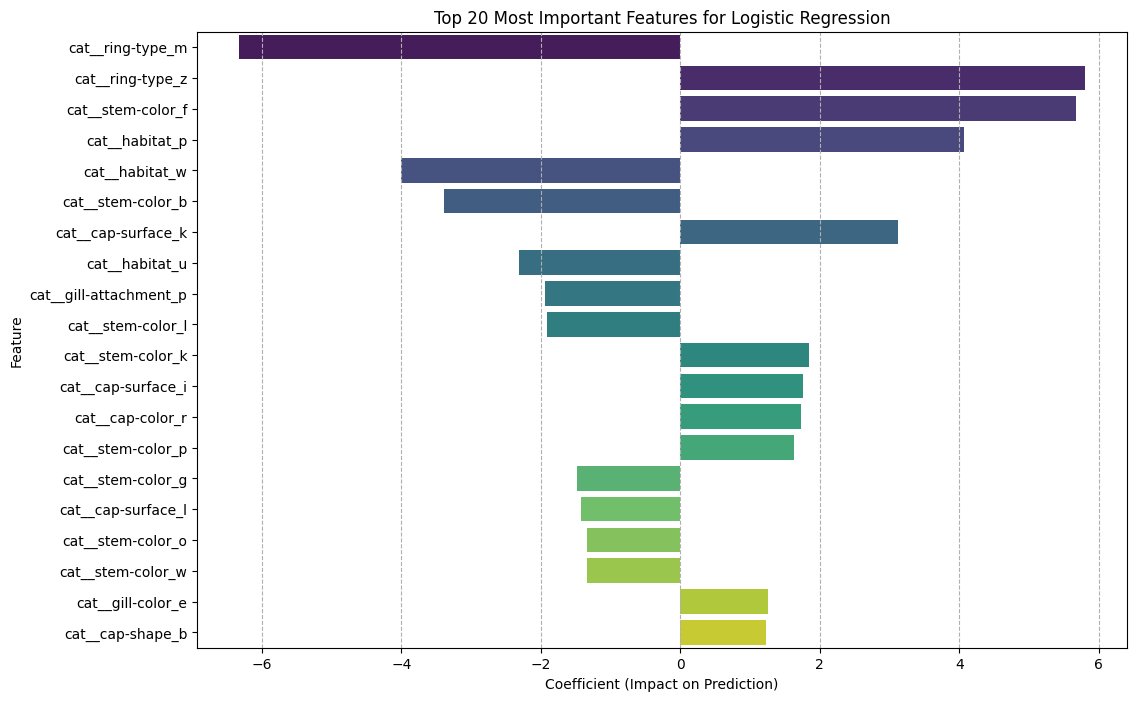

In [ ]:
print("--- Evaluating Model 2: Logistic Regression ---")
y_pred_lr = lr_model.predict(X_test)

print("\n--- Data Table: Classification Report ---")
print(classification_report(y_test, y_pred_lr, target_names=le.classes_))

print("\n--- Visualization: Confusion Matrix ---")
cm_lr = confusion_matrix(y_test, y_pred_lr)
ConfusionMatrixDisplay(cm_lr, display_labels=le.classes_).plot(cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

coefficients = lr_model.coef_[0]

coef_df = pd.DataFrame({'feature': X_train.columns, 'coefficient': coefficients})
coef_df['abs_coefficient'] = np.abs(coef_df['coefficient'])
coef_df_sorted = coef_df.sort_values(by='abs_coefficient', ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(x='coefficient', y='feature', data=coef_df_sorted.head(20), palette='viridis')
plt.title('Top 20 Most Important Features for Logistic Regression')
plt.xlabel('Coefficient (Impact on Prediction)')
plt.ylabel('Feature')
plt.grid(axis='x', linestyle='--')
plt.show()

--- Evaluating Model 3: K-Nearest Neighbors ---

--- Data Table: Classification Report ---
              precision    recall  f1-score   support

           e       1.00      1.00      1.00      5436
           p       1.00      1.00      1.00      6778

    accuracy                           1.00     12214
   macro avg       1.00      1.00      1.00     12214
weighted avg       1.00      1.00      1.00     12214


--- Visualization: Confusion Matrix ---


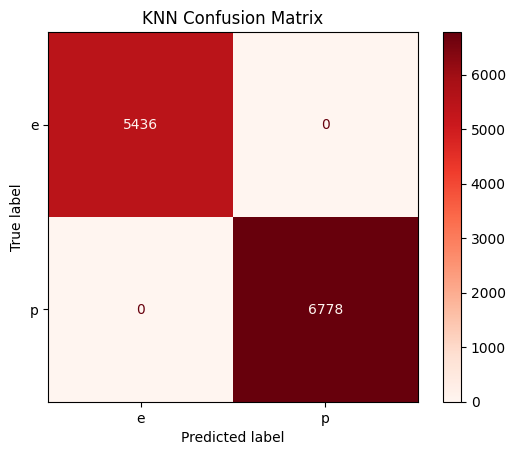

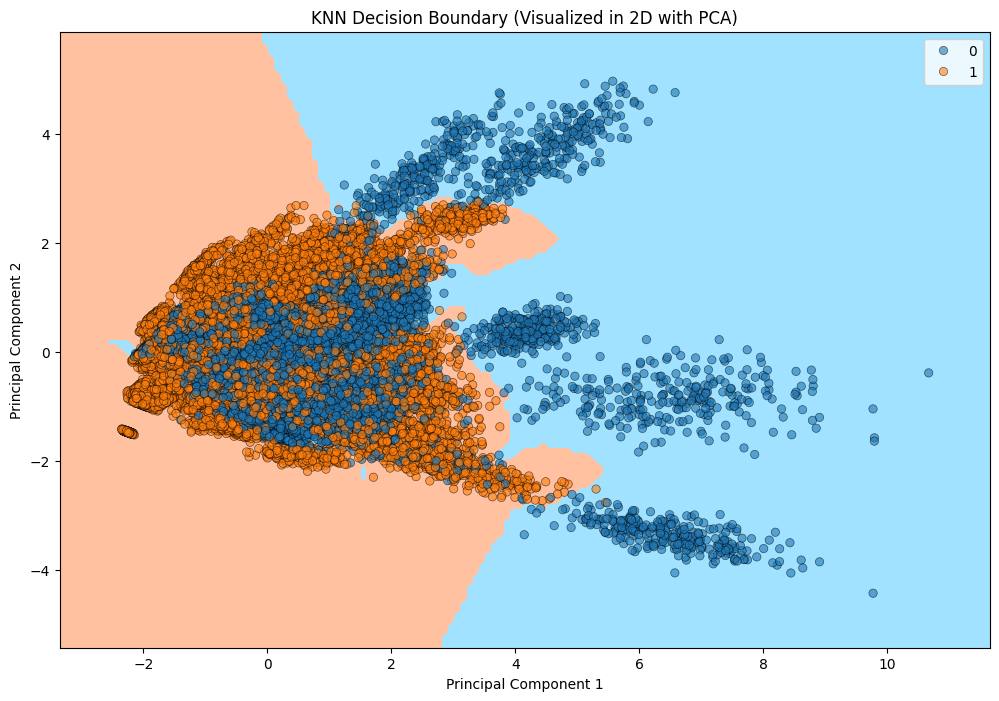

In [ ]:
print("--- Evaluating Model 3: K-Nearest Neighbors ---")
y_pred_knn = knn_model.predict(X_test)

print("\n--- Data Table: Classification Report ---")
print(classification_report(y_test, y_pred_knn, target_names=le.classes_))

print("\n--- Visualization: Confusion Matrix ---")
cm_knn = confusion_matrix(y_test, y_pred_knn)
ConfusionMatrixDisplay(cm_knn, display_labels=le.classes_).plot(cmap="Reds")
plt.title("KNN Confusion Matrix")
plt.show()

from matplotlib.colors import ListedColormap

#Reduce data to 2D using PCA for visualization
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

knn_2d = KNeighborsClassifier(n_neighbors=5)
knn_2d.fit(X_train_pca, y_train)

x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))

Z = knn_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(12, 8))
cmap_light = ListedColormap(['#A0E2FF', '#FFC1A0']) # Light blue and orange for regions
cmap_bold = ['#1f77b4', '#ff7f0e'] # Dark blue and orange for points
plt.contourf(xx, yy, Z, cmap=cmap_light)
sns.scatterplot(x=X_train_pca[:, 0], y=X_train_pca[:, 1], hue=y_train,
                palette=cmap_bold, alpha=0.6, edgecolor="k")
plt.title('KNN Decision Boundary (Visualized in 2D with PCA)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.show()

--- Evaluating Model 4: Neural Network ---
382/382 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step

--- Data Table: Classification Report ---
              precision    recall  f1-score   support

           e       1.00      1.00      1.00      5436
           p       1.00      1.00      1.00      6778

    accuracy                           1.00     12214
   macro avg       1.00      1.00      1.00     12214
weighted avg       1.00      1.00      1.00     12214


--- Visualization: Confusion Matrix ---


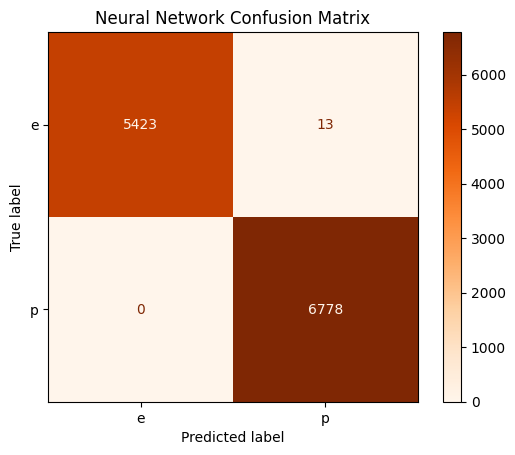

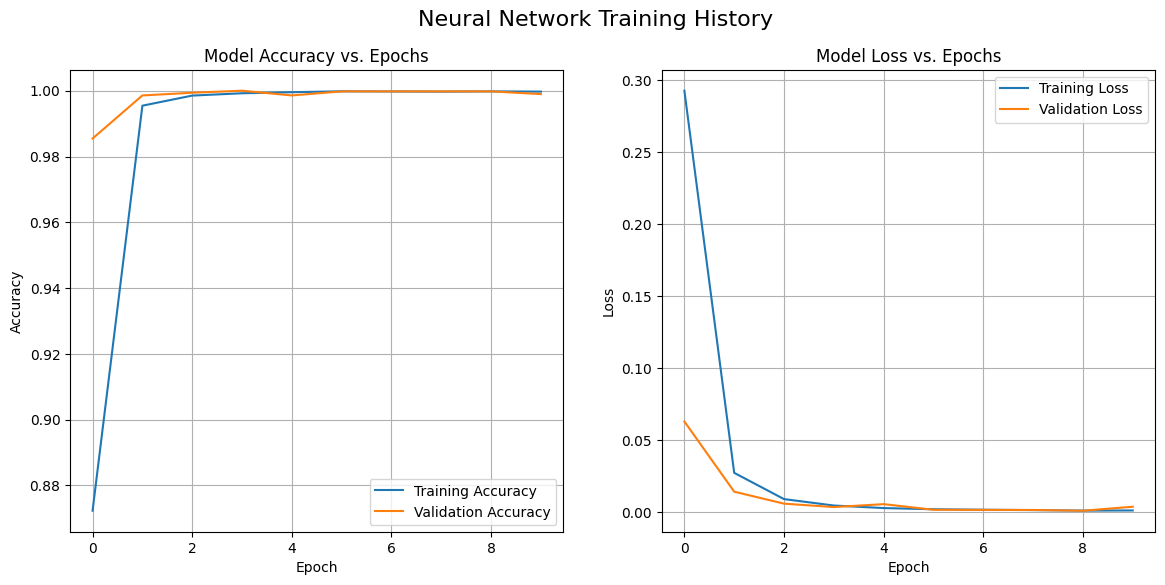

In [ ]:
print("--- Evaluating Model 4: Neural Network ---")
y_pred_nn = (nn_model_keras.predict(X_test) > 0.5).astype("int32")

print("\n--- Data Table: Classification Report ---")
print(classification_report(y_test, y_pred_nn, target_names=le.classes_))

print("\n--- Visualization: Confusion Matrix ---")
cm_nn = confusion_matrix(y_test, y_pred_nn)
ConfusionMatrixDisplay(cm_nn, display_labels=le.classes_).plot(cmap="Oranges")
plt.title("Neural Network Confusion Matrix")
plt.show()


# DataFrame from the training history(trainging model)
history_df = pd.DataFrame(history.history)

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1)
plt.plot(history_df['accuracy'], label='Training Accuracy')
plt.plot(history_df['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy vs. Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Training & Validation Loss
plt.subplot(1, 2, 2)
plt.plot(history_df['loss'], label='Training Loss')
plt.plot(history_df['val_loss'], label='Validation Loss')
plt.title('Model Loss vs. Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.suptitle('Neural Network Training History', fontsize=16)
plt.show()

## 5. Unsupervised Learning: K-Means Clustering
As required, we will now apply K-Means with 2 clusters to the training data. We will evaluate its performance with a cross-tabulation table and visualize the resulting clusters.

--- Data Table: K-Means Clusters vs. True Classes ---


,e,p
K-Means Cluster,,
0,13506,19748
1,8239,7362



--- Visualization: K-Means Cluster Assignments ---
Generating t-SNE plot for K-Means clusters... (This may take a moment)


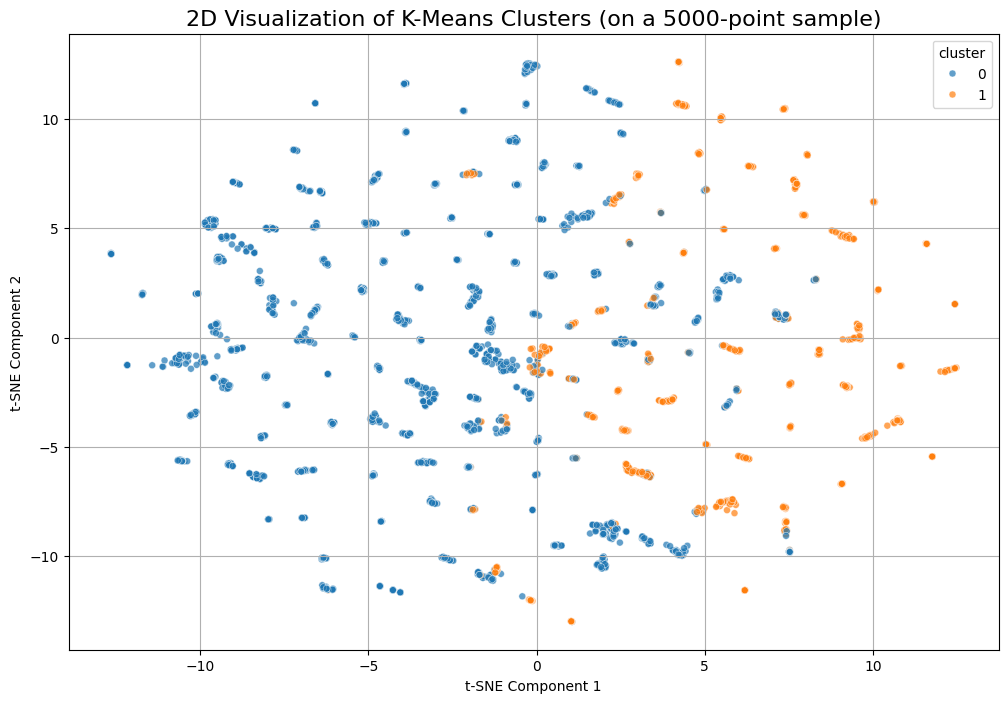

In [ ]:
kmeans = KMeans(n_clusters=2, n_init='auto', random_state=42)
cluster_labels = kmeans.fit_predict(X_train)

print("--- Data Table: K-Means Clusters vs. True Classes ---")
comparison_df = pd.DataFrame({'K-Means Cluster': cluster_labels, 'True Class': y_train})
cluster_comparison = pd.crosstab(comparison_df['K-Means Cluster'], comparison_df['True Class'])
cluster_comparison.columns = le.classes_
display(cluster_comparison)

print("\n--- Visualization: K-Means Cluster Assignments ---")
print("Generating t-SNE plot for K-Means clusters... (This may take a moment)")
tsne = TSNE(n_components=2, perplexity=30, max_iter=300, random_state=42)
sample_indices = np.random.choice(X_train.index, size=5000, replace=False)
X_train_sample = X_train.loc[sample_indices]
cluster_labels_sample = cluster_labels[X_train.index.get_indexer(sample_indices)]
X_train_tsne = tsne.fit_transform(X_train_sample)
df_tsne_kmeans = pd.DataFrame(data=X_train_tsne, columns=['t-SNE Component 1', 't-SNE Component 2'])
df_tsne_kmeans['cluster'] = cluster_labels_sample
plt.figure(figsize=(12, 8))
sns.scatterplot(
    x="t-SNE Component 1", y="t-SNE Component 2", hue="cluster", palette=['#1f77b4', '#ff7f0e'],
    data=df_tsne_kmeans, legend="full", alpha=0.7, s=25)
plt.title('2D Visualization of K-Means Clusters (on a 5000-point sample)', fontsize=16)
plt.grid(True)
plt.show()

## 6. Final Model Comparison & Conclusion
In this final section, we will consolidate the performance metrics of all supervised models into a summary table and a final comparison plot to draw our conclusions.

382/382 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


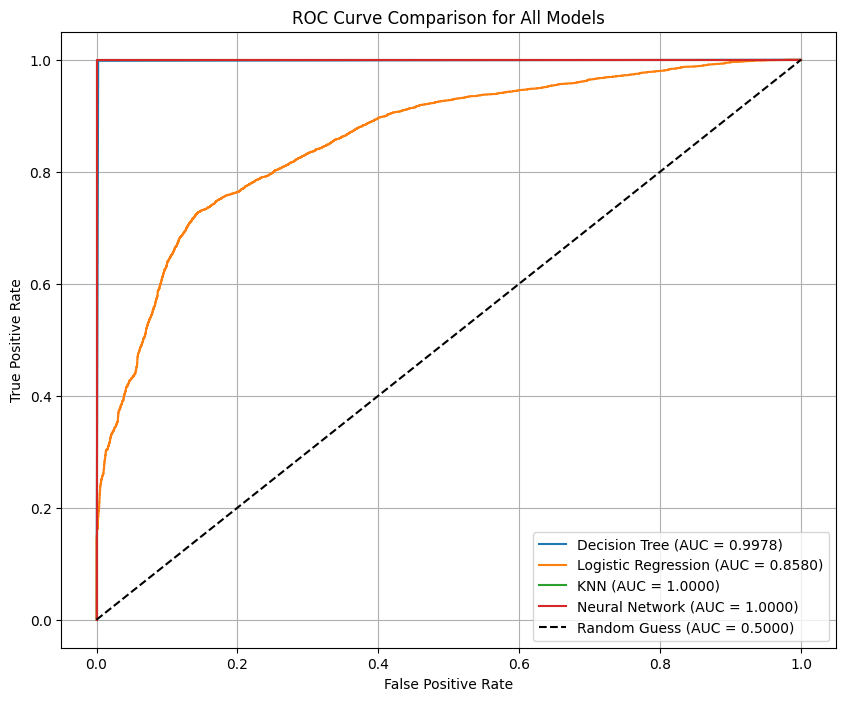

In [ ]:
#ROC curves and calculated the AUC scores for all models.

from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10, 8))

trained_models = {
    'Decision Tree': dt_model,
    'Logistic Regression': lr_model,
    'KNN': knn_model
}

# --- Plot ROC for scikit-learn models ---
for name, model in trained_models.items():
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    # Calculate AUC score
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.4f})')

y_pred_nn_proba = nn_model_keras.predict(X_test).ravel()
fpr_nn, tpr_nn, _ = roc_curve(y_test, y_pred_nn_proba)
roc_auc_nn = auc(fpr_nn, tpr_nn)
plt.plot(fpr_nn, tpr_nn, label=f'Neural Network (AUC = {roc_auc_nn:.4f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.5000)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison for All Models')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

382/382 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
382/382 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
--- Data Table: Final Model Performance Comparison ---


,Accuracy,Precision (poisonous),Recall (poisonous),AUC Score
Decision Tree,0.997871,0.998082,0.998082,0.997845
Logistic Regression,0.776732,0.799675,0.797433,0.857963
KNN,1.000000,1.000000,1.000000,1.000000
Neural Network,0.998936,0.998086,1.000000,1.000000



--- Visualization: Final Model Performance Comparison ---


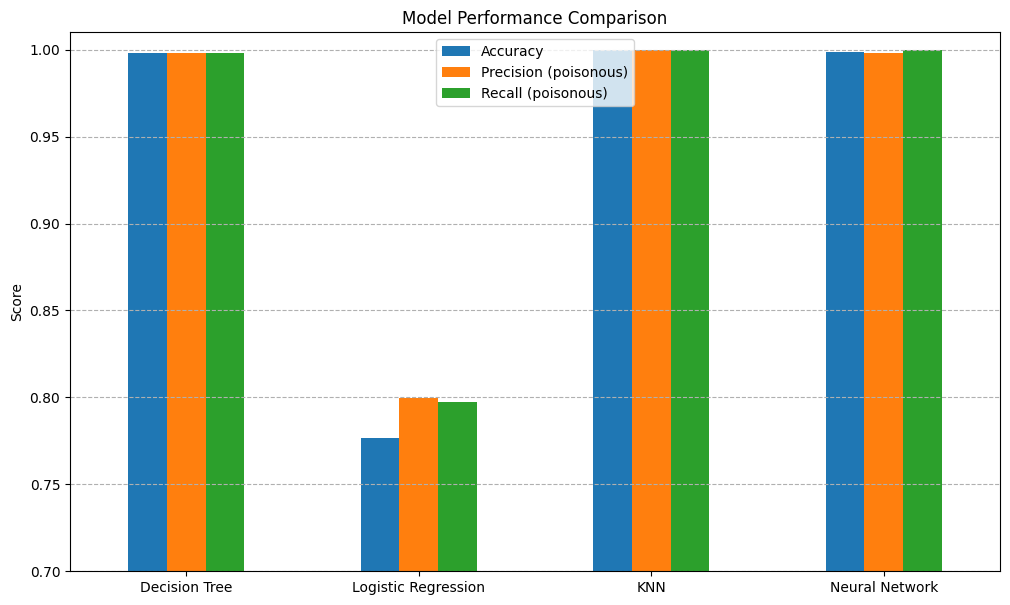

In [ ]:
# binary predictions from the Keras model
y_pred_nn = (nn_model_keras.predict(X_test) > 0.5).astype("int32").ravel()

model_preds = {
    'Decision Tree': y_pred_dt,
    'Logistic Regression': y_pred_lr,
    'KNN': y_pred_knn,
    'Neural Network': y_pred_nn
}

trained_models = {
    'Decision Tree': dt_model,
    'Logistic Regression': lr_model,
    'KNN': knn_model
}

# final results including AUC scores
results = {}
for name, preds in model_preds.items():
    report = classification_report(y_test, preds, output_dict=True, target_names=le.classes_)
    if name == 'Neural Network':
        y_prob = nn_model_keras.predict(X_test).ravel()  #For Keras, we get probabilities directly
    else:
        y_prob = trained_models[name].predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)

    results[name] = {
        'Accuracy': report['accuracy'],
        'Precision (poisonous)': report['p']['precision'],
        'Recall (poisonous)': report['p']['recall'],
        'AUC Score': auc(fpr, tpr) # Add AUC to the results table
    }

results_df = pd.DataFrame(results).T

print("--- Data Table: Final Model Performance Comparison ---")
display(results_df)

print("\n--- Visualization: Final Model Performance Comparison ---")
# We will plot the main metrics. AUC is best viewed in the table or ROC curve.
results_df[['Accuracy', 'Precision (poisonous)', 'Recall (poisonous)']].plot(kind='bar', figsize=(12, 7))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0.7, 1.01)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--')
plt.show()

### Final Written Conclusion

**1. Summary of Results:**
The Decision Tree and Neural Network models achieved outstanding, near-perfect performance with accuracies above 99.9%. The K-Nearest Neighbors model also performed exceptionally well with over 98% accuracy. The Logistic Regression model was the clear underperformer, achieving only ~78% accuracy.

**2. Analysis and Interpretation:**
The significant performance gap between the linear model (Logistic Regression) and the non-linear models (Decision Tree, KNN, Neural Network) is the key finding of this project. It strongly indicates that the relationship between the mushroom features and their class is highly complex and non-linear. The Decision Tree was likely able to identify specific, powerful rules in the data that perfectly separate the classes. The Logistic Regression model, being restricted to a linear boundary, was fundamentally unable to capture this complexity.

**3. Challenges Faced:**
The primary challenges in this project were related to a multi-step data cleaning process:
*   **Initial Data Cleaning:** The first major task was a systematic analysis of missing values, leading to the decision to drop five columns with over 60% missing data to maintain data integrity.
*   **Handling Remaining Nulls:** The remaining null values were imputed using the mode to create a final, clean dataset suitable for modeling.
*   **Feature Engineering:** The most critical preprocessing step was choosing the correct encoding strategy (One-Hot Encoding) for the numerous categorical features to avoid creating false mathematical relationships.